In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

data = fetch_california_housing()
df = pd.DataFrame(data.data, columns = data.feature_names)
df["MedHouseVal"] = data.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


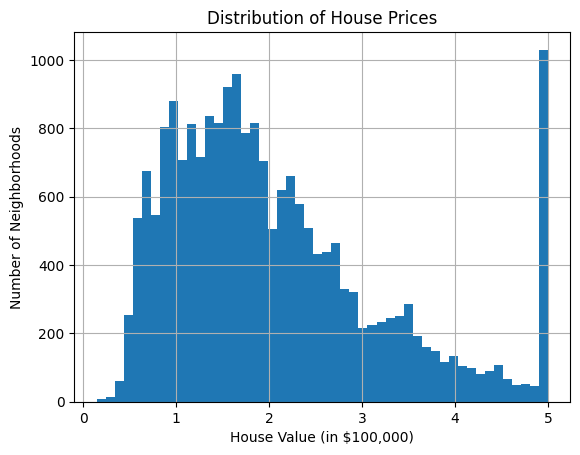

In [2]:
df["MedHouseVal"].hist(bins = 50)
plt.title("Distribution of House Prices")
plt.xlabel("House Value (in $100,000)")
plt.ylabel("Number of Neighborhoods")
plt.show()

In [3]:
print((df["MedHouseVal"] >= 5.0).sum())
X =  df.drop(columns = ["MedHouseVal"])
y = df["MedHouseVal"]
print(X.shape)
print(y.shape)

992
(20640, 8)
(20640,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
print(X_train.shape)
print(X_test.shape)

(16512, 8)
(4128, 8)


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [6]:
pred = model.predict(X_test)
print(pred[:5])
print(y_test[:5])

[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64


In [7]:
print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
print("R2:", r2_score(y_test, pred))

RMSE: 0.7455813830127764
R2: 0.5757877060324508


In [8]:
rf = RandomForestRegressor(n_estimators = 100, random_state = 42, n_jobs = -1)
rf.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [9]:
rf_pred = rf.predict(X_test)
print(rf_pred[:5])
print(y_test[:5])

[0.5095    0.74161   4.9232571 2.52961   2.27369  ]
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64


In [10]:
print("RMSE:", mean_squared_error(y_test, rf_pred) ** 0.5)
print("R2:", r2_score(y_test, rf_pred))
print(rf.feature_importances_)
pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

RMSE: 0.5053399773665033
R2: 0.8051230593157366
[0.52487148 0.05459322 0.04427185 0.02960631 0.03064978 0.13844281
 0.08893574 0.08862881]


MedInc        0.524871
AveOccup      0.138443
Latitude      0.088936
Longitude     0.088629
HouseAge      0.054593
AveRooms      0.044272
Population    0.030650
AveBedrms     0.029606
dtype: float64

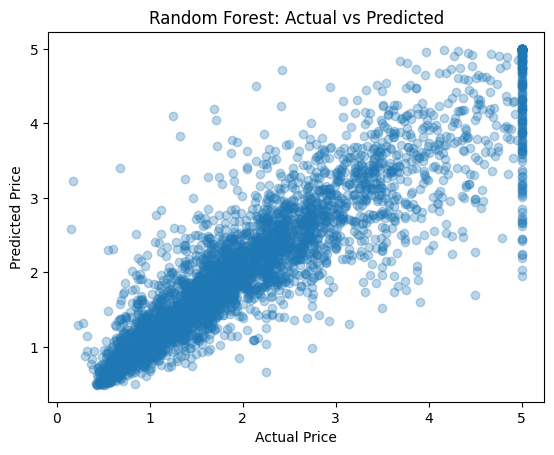

In [11]:
plt.scatter(y_test, rf_pred, alpha = 0.3)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

In [12]:
train_pred = rf.predict(X_train)
print("Train RMSE:", mean_squared_error(y_train, train_pred) ** 0.5)

Train RMSE: 0.18795619089802199


Linear Regression: RMSE 0.7456, R² 0.5758
Random Forest: RMSE 0.5053, R² 0.8051
Top feature: median income